In [299]:
import numpy as np
import pandas as pd

## Ponto de Partida e Reflexões Iniciais

Bases na ordem do tratamento:

- `base_cadastral`: Cada linha representa um cliente único
- `historico_parcelas`: Registros de parcelas por par cliente–contrato, com data e valor pago quando disponíveis.
- `historico_emprestimos`: apresenta historico de contratos anteriores de cada cliente. Cada linha equivale a um par cliente-contrato (pk = [`id_cliente`, `id_contrato`])
- `base_submissao`: Cada linha representa **o contrato mais recente de um cliente** que está **em análise** e deverão ser avaliados pelo modelo (previsão de inadimplência)


## Ingestão + Tratamento de dados inicial

In [300]:
path_dados = r"C:\Python - Projects\Aulas WeCogno\Trabalho - Inadimplência\data\raw"

base_cadastral = pd.read_parquet(rf"{path_dados}\base_cadastral.parquet")
historico_parcelas = pd.read_parquet(rf"{path_dados}\historico_parcelas.parquet")
historico_emprestimos = pd.read_parquet(rf"{path_dados}\historico_emprestimos.parquet")
base_submissao = pd.read_parquet(rf"{path_dados}\base_submissao.parquet")

In [ ]:
print(f"base_cadastral: {base_cadastral['id_cliente'].nunique()} clientes distintos")
print(f"historico_parcelas: {historico_parcelas['id_cliente'].nunique()} clientes distintos")
print(f"historico_emprestimos: {historico_emprestimos['id_cliente'].nunique()} clientes distintos")
print(f"base_submissao: {base_submissao['id_cliente'].nunique()} clientes distintos")

Todos os clientes da base_submissao estão presentes na base_cadastral?

### `Base_cadastral`

In [302]:
base_cadastral

,id_cliente,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
0,100023,Feminino,1994-01-30,1,2.0,"90.000,00",Servidor público,Equipe administrativa,Educação infantil,Ensino superior,Solteiro,Casa ou apartamento,Não,Sim,2,2
1,100031,Feminino,1973-11-13,0,1.0,"112.500,00",Assalariado,Cozinheiros,Entidade empresarial tipo 3,Ensino médio,Viúvo,Casa ou apartamento,Não,Sim,3,2
2,100056,Masculino,1975-02-19,0,2.0,"360.000,00",Assalariado,Operários,Transporte tipo 2,Ensino médio,Casado,Casa ou apartamento,Sim,Sim,2,2
3,100069,Masculino,1986-04-10,1,2.0,"360.000,00",Assalariado,Operários,Transporte tipo 4,Ensino médio,Separado,Casa ou apartamento,Sim,Sim,2,2
4,100085,Masculino,1994-07-05,1,3.0,"-17.673,00",Assalariado,Motoristas,Entidade empresarial tipo 1,Ensino médio,Casado,Casa ou apartamento,Não,Sim,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50595,201363,Feminino,1993-06-21,0,1.0,"170.160,86",Assalariado,Equipe administrativa,Comércio tipo 7,Ensino médio,Separado,Casa ou apartamento,Sim,Não,1,1
50596,465888,Masculino,1992-05-18,4,5.0,"114.384,85",Assalariado,Operários,Escola,Ensino médio,Casado,Apartamento municipal,Não,Não,2,2
50597,463408,Masculino,1983-09-23,2,4.0,"189.593,34",Assalariado,NaN,Não informado,Ensino superior,União estável,Casa ou apartamento,Não,Não,2,3
50598,213846,Masculino,1995-07-20,1,3.0,"164.369,16",Assalariado,Operários,Construção,Ensino médio,Casado,Casa ou apartamento,Sim,Sim,2,2


Analisando inicialmente as descrições de cada tabela, podemos inferir quais deverão ser os tipos de variáveis para cada coluna que possuímos.

Coluna|Descricao|Tipo de variável|Datatype provável|
|-|-|-|-|
|`id_cliente`|Identificador do cliente (espera-se 1 valor por cliente)|Numérico|int|
|`sexo`|Sexo do cliente: "Feminino", "Masculino" ou "Não informado"|Categórica nominal|str|
|`data_nascimento`|Data de nascimento do cliente|Temporal (data)|datetime|
|`qtd_filhos`|Quantidade de filhos declarados pelo cliente|Numérica discreta|int|
|`qtd_membros_familia`|Quantidade total de membros da família|Numérica discreta|int|
|`renda_anual`|Renda anual declarada pelo cliente|Numérica contínua|float|
|`tipo_renda`|Fonte de renda do cliente ("Assalariado", "Associado comercial", "Aposentado", "Servidor público" ou "Autônomo")|Categórica nominal|str|
|`ocupacao`|Ocupação profissional do cliente ("Operários", "Equipe de vendas", "Gerentes" ou "Motoristas")|Categórica nominal|str|
|`tipo_organizacao`|Classificação da organização do trabalho do cliente ("Autônomo", "Transporte tipo 1", etc)|Categórica nominal|str|
|`nivel_educacao`|Escolaridade|Categórica ordinal|category (ordered=True)|
|`estado_civil`|Estado civil|Categórica nominal|str|
|`tipo_moradia`|Situação de moradia ("Casa ou apartamento", "Mora com os pais", "Imóvel alugado", "Apartamento municipal", "Apartamento funcional" ou "Apartamento cooperativo")|Categórica nominal|str|
|`possui_carro`|Indica posse de carro ("Sim", "Não" ou "Não informado")|Binária|int|
|`possui_imovel`|Indica posse de imóvel ("Sim", "Não" ou "Não informado")|Binária|int|
|`nota_regiao_cliente`|Nota de risco da região de residência do cliente|Categórica ordinal|category (ordered=True)|
|`nota_regiao_cliente_cidade`|Nota de risco da região de residência do cliente, considerando a cidade|Categórica ordinal|category (ordered=True)|

Na implementação, `id_cliente` e `qtd_filhos` já são lidas como `int64` e recebem apenas validações de domínio. As notas regionais são convertidas de `int64` para `category`, com ordem explícita `1 < 2 < 3`. `qtd_membros_familia` chega como `float64` e é convertida para `Int64`, com suporte a nulos. `float64` representa a renda e `string` representa as colunas indicadas como `str`. O tratamento segue os grupos de colunas binárias, datetime, categóricas ordinais, categóricas nominais (texto), numéricas inteiras e numéricas float. Dentro de cada grupo, as colunas seguem a ordem desta tabela.


In [303]:
base_cadastral.info()

<class 'pandas.DataFrame'>
RangeIndex: 50600 entries, 0 to 50599
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id_cliente                  50600 non-null  int64  
 1   sexo                        50600 non-null  str    
 2   data_nascimento             50600 non-null  str    
 3   qtd_filhos                  50600 non-null  int64  
 4   qtd_membros_familia         50600 non-null  float64
 5   renda_anual                 50600 non-null  str    
 6   tipo_renda                  50600 non-null  str    
 7   ocupacao                    34894 non-null  str    
 8   tipo_organizacao            50600 non-null  str    
 9   nivel_educacao              50600 non-null  str    
 10  estado_civil                50600 non-null  str    
 11  tipo_moradia                50600 non-null  str    
 12  possui_carro                50600 non-null  str    
 13  possui_imovel               50600 non-null

#### Colunas Binárias

`Sim` recebe `1` e `Não` recebe `0`, padronizando espaços e maiúsculas. Valores não informados ficam nulos. O tipo `Int64` aceita inteiros e valores ausentes.


##### `possui_carro`

In [304]:
base_cadastral["possui_carro"].value_counts(dropna=False)

possui_carro
Não              33028
Sim              17319
Não                 56
nao                 53
sim                 49
não informado       49
SIM                 46
Name: count, dtype: int64

In [305]:
base_cadastral["possui_carro"] = (
    base_cadastral["possui_carro"]
    .astype("string")
    .str.lower()
    .str.strip()
    .map({"sim": 1, "não": 0, "nao": 0, "1": 1, "0": 0})
    .astype("Int64")
)

base_cadastral["possui_carro"].value_counts(dropna=False)


possui_carro
0       33137
1       17414
<NA>       49
Name: count, dtype: Int64

##### `possui_imovel`

In [306]:
base_cadastral["possui_imovel"].value_counts(dropna=False)

possui_imovel
Sim              34925
Não              15422
Não                 58
não informado       54
SIM                 50
nao                 47
sim                 44
Name: count, dtype: int64

In [307]:
base_cadastral["possui_imovel"] = (
    base_cadastral["possui_imovel"]
    .astype("string")
    .str.lower()
    .str.strip()
    .map({"sim": 1, "não": 0, "nao": 0, "1": 1, "0": 0})
    .astype("Int64")
)

base_cadastral["possui_imovel"].value_counts(dropna=False)


possui_imovel
1       35019
0       15527
<NA>       54
Name: count, dtype: Int64

#### Datetime


##### Data Nascimento

As datas válidas observadas seguem o formato `AAAA-MM-DD`. A conversão transforma valores inválidos, como `31/02/1990`, em `NaT` e preserva uma cópia dos valores originais para conferência.

A coluna binária `data_nascimento_invalida` recebe `1` quando um valor preenchido na origem falha na conversão e `0` para datas válidas. Valores já nulos na origem recebem `0`, pois representam ausência de informação.


Usamos 4 de fevereiro de 2025, a primeira data válida da base de submissão, como referência para a idade em anos completos. `idade_menor_18` sinaliza nascimentos posteriores ao limite de 18 anos, inclusive datas futuras, e essas datas ficam como `NaT`. `idade_maior_100` sinaliza quem já completou 101 anos, preservando a data de nascimento.

In [308]:
# Checando se a coluna "data_nascimento" já é dt64
if not pd.api.types.is_datetime64_any_dtype(base_cadastral["data_nascimento"]):
    datas_nascimento_originais = base_cadastral["data_nascimento"].copy()

datas_originais = datas_nascimento_originais.astype("string").str.strip()

# Convertendo as datas para o formato datetime
datas_convertidas = pd.to_datetime(datas_originais, format="%Y-%m-%d", errors="coerce")

# Identifica falhas de conversão antes de aplicar as regras de idade.
datas_invalidas = datas_originais.notna() & datas_convertidas.isna()
base_cadastral["data_nascimento_invalida"] = datas_invalidas.astype("int8")

data_referencia_idade = pd.Timestamp("2025-02-04")
menor_18 = datas_convertidas.gt(data_referencia_idade - pd.DateOffset(years=18))
maior_100 = datas_convertidas.le(data_referencia_idade - pd.DateOffset(years=101))

base_cadastral["idade_menor_18"] = menor_18.astype("int8")
base_cadastral["idade_maior_100"] = maior_100.astype("int8")
base_cadastral["data_nascimento"] = datas_convertidas.mask(menor_18)


In [309]:
# datas_invalidas -> ocorrem se a informação original não é nula mas a conversão não é possível (valor incoerente)
datas_invalidas = base_cadastral["data_nascimento_invalida"].eq(1)

print(f"Datas ausentes na origem: {datas_originais.isna().sum()}")
print(f"Datas inválidas encontradas: {datas_invalidas.sum()}")
display(datas_nascimento_originais[datas_invalidas].value_counts().rename("quantidade de datas inválidas").to_frame())

print(f"Datas anuladas pela regra de idade mínima: {base_cadastral['idade_menor_18'].sum()}")
print(f"Registros com idade acima de 100 anos: {base_cadastral['idade_maior_100'].sum()}")


Datas ausentes na origem: 0
Datas inválidas encontradas: 38


,quantidade de datas inválidas
data_nascimento,
31/02/1990,38


Datas anuladas pela regra de idade mínima: 75
Registros com idade acima de 100 anos: 38


#### Categóricas Ordinais


##### `nota_regiao_cliente`

Convertida para `category`, com categorias ordenadas em `1 < 2 < 3` (`ordered=True`). Valores fora desse conjunto ficam nulos. A ordem segue os códigos das notas.


In [310]:
base_cadastral["nota_regiao_cliente"] = pd.Categorical(
    base_cadastral["nota_regiao_cliente"],
    categories=[1, 2, 3],
    ordered=True
)

base_cadastral["nota_regiao_cliente"].value_counts(dropna=False).sort_index()


nota_regiao_cliente
1     5433
2    35504
3     9663
Name: count, dtype: int64

##### `nota_regiao_cliente_cidade`

Convertida para `category`, com categorias ordenadas em `1 < 2 < 3` (`ordered=True`). Valores fora desse conjunto ficam nulos. A ordem segue os códigos das notas.


In [311]:
base_cadastral["nota_regiao_cliente_cidade"] = pd.Categorical(
    base_cadastral["nota_regiao_cliente_cidade"],
    categories=[1, 2, 3],
    ordered=True
)

base_cadastral["nota_regiao_cliente_cidade"].value_counts(dropna=False).sort_index()


nota_regiao_cliente_cidade
1     5520
2    35919
3     9161
Name: count, dtype: int64

##### `nivel_educacao`

Convertida para `category` com `ordered=True`, na ordem `ensino fundamental` < `ensino médio` < `ensino superior incompleto` < `ensino superior completo` < `pós-graduacao`.

O rótulo `pós-graduação` passa a `pós-graduacao`. Eventuais marcadores como `nao informado` são preservados após os níveis conhecidos; sua posição não tem interpretação de escolaridade. Esses marcadores não ocorrem na coluna da base atual.


In [312]:
ordem_nivel_educacao = [
    "ensino fundamental",
    "ensino médio",
    "ensino superior incompleto",
    "ensino superior",
    "pós-graduação"
]

base_cadastral["nivel_educacao"] = (
    base_cadastral["nivel_educacao"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

# Preserva eventuais marcadores de texto, listados depois dos niveis conhecidos.
rotulos_fora_escala = (
    base_cadastral["nivel_educacao"].dropna()
    .loc[lambda valores: ~valores.isin(ordem_nivel_educacao)]
    .unique().tolist()
)
base_cadastral["nivel_educacao"] = pd.Categorical(
    base_cadastral["nivel_educacao"],
    categories=ordem_nivel_educacao + rotulos_fora_escala,
    ordered=True
)

base_cadastral["nivel_educacao"].value_counts(dropna=False).sort_index()


nivel_educacao
ensino fundamental              727
ensino médio                  35772
ensino superior incompleto     1757
ensino superior               12269
pós-graduação                    75
Name: count, dtype: int64

#### Categóricas Nominais (texto)

Usamos o dtype `string` do pandas, preservando os valores originalmente nulos. Padronizamos maiúsculas e minúsculas, removemos espaços nas extremidades e reduzimos espaços consecutivos. Os textos ficam em minúsculas, com os acentos preservados nas categorias.

As variações de `Não informado`, `NÃO INFORMADO` e `nao informado` ficam como `nao informado`. Esse marcador permanece como texto para avaliação posterior. Textos vazios também são preservados nesta etapa.

Para recuperar marcadores que já tenham sido convertidos em nulos durante uma execução anterior, reexecute o notebook a partir da leitura das tabelas.


##### `sexo`

 `Feminino `, `feminino` e `MASCULINO`.


In [313]:
base_cadastral["sexo"] = (
    base_cadastral["sexo"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

base_cadastral["sexo"].value_counts(dropna=False)


sexo
feminino         32836
masculino        17713
nao informado       51
Name: count, dtype: int64[pyarrow]

##### `tipo_renda`

Unificamos variações de escrita e corrigimos `Autonomo` para `autônomo`.


In [314]:
base_cadastral["tipo_renda"] = (
    base_cadastral["tipo_renda"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
    .replace({"autonomo": "autônomo"})
)

base_cadastral["tipo_renda"].value_counts(dropna=False)


tipo_renda
assalariado            25600
associado comercial    11557
aposentado              9270
servidor público        3694
autônomo                 410
nao informado             60
desempregado               3
licença maternidade        3
estudante                  2
empresário                 1
Name: count, dtype: int64[pyarrow]

##### `ocupacao`

Substituir nulos por não-informado


In [315]:
base_cadastral["ocupacao"] = (
    base_cadastral["ocupacao"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado",
              np.nan: "nao informado"})
)

base_cadastral["ocupacao"].value_counts(dropna=False)


ocupacao
nao informado                      15706
operários                           9026
equipe de vendas                    5570
equipe administrativa               4636
gerentes                            3684
motoristas                          3221
técnicos especializados             2025
contadores                          1695
profissionais de saúde              1488
equipe de segurança                  919
cozinheiros                          768
equipe de limpeza                    590
serviços particulares                363
operários de baixa qualificação      257
garçons e atendentes de bar          202
secretárias                          184
corretores imobiliários              105
equipe de tecnologia                  85
equipe de recursos humanos            76
Name: count, dtype: int64[pyarrow]

##### `tipo_organizacao`

Preservamos as categorias de organização, incluindo `outro`, e padronizamos o marcador de ausência como `nao informado`.

In [316]:
base_cadastral["tipo_organizacao"] = (
    base_cadastral["tipo_organizacao"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

base_cadastral["tipo_organizacao"].value_counts(dropna=False)


tipo_organizacao
entidade empresarial tipo 3    11341
nao informado                  10001
autônomo                        6638
outro                           3081
governo                         2214
saúde                           2108
escola                          1868
comércio tipo 7                 1621
entidade empresarial tipo 2     1331
construção                       885
educação infantil                866
entidade empresarial tipo 1      813
transporte tipo 4                693
comércio tipo 3                  458
segurança                        426
indústria tipo 9                 398
indústria tipo 3                 393
habitação                        375
indústria tipo 11                345
forças armadas                   322
banco                            312
transporte tipo 2                305
polícia                          304
correios                         291
agricultura                      286
comércio tipo 2                  258
ministérios de segura

Podemos criar uma nova coluna "tipo_organizacao_agrupado" para juntar os termos similares (por exemplo: `transporte tipo 1` e `transporte tipo 2` são lidos como `transporte`, etc).



##### `tipo_organizacao_setor`

Criamos uma coluna de texto com o setor agrupado, removendo o sufixo `tipo` seguido do número. Por exemplo, `transporte tipo 1` e `transporte tipo 2` passam a `transporte`. O mesmo vale para `indústria`, `comércio` e `entidade empresarial`.

Categorias sem esse sufixo, o marcador `nao informado` e nulos originais são preservados. `tipo_organizacao` mantém os subtipos para comparações dentro de cada setor agrupado.


In [317]:
base_cadastral["tipo_organizacao_setor"] = (
    base_cadastral["tipo_organizacao"]
    .str.replace(r"\s+tipo\s+\d+\s*$", "", regex=True)
)

base_cadastral["tipo_organizacao_setor"].value_counts(dropna=False)


tipo_organizacao_setor
entidade empresarial        13485
nao informado               10001
autônomo                     6638
outro                        3081
comércio                     2496
governo                      2214
saúde                        2108
escola                       1868
indústria                    1804
transporte                   1196
construção                    885
educação infantil             866
segurança                     426
habitação                     375
forças armadas                322
banco                         312
polícia                       304
correios                      291
agricultura                   286
ministérios de segurança      242
restaurante                   238
serviços                      212
universidade                  163
hotel                         149
energia elétrica              120
telecomunicações               87
serviços de emergência         80
seguro                         70
publicidade              

##### `estado_civil`

Padronizamos os rótulos e mantemos o marcador de ausência como `nao informado`.

In [318]:
base_cadastral["estado_civil"] = (
    base_cadastral["estado_civil"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

base_cadastral["estado_civil"].value_counts(dropna=False)


estado_civil
casado           32021
solteiro          7615
união estável     4942
separado          3277
viúvo             2595
nao informado      150
Name: count, dtype: int64[pyarrow]

##### `tipo_moradia`

Padronizamos os rótulos das categorias de moradia.


In [319]:
base_cadastral["tipo_moradia"] = (
    base_cadastral["tipo_moradia"]
    .astype("string")
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

base_cadastral["tipo_moradia"].value_counts(dropna=False)


tipo_moradia
casa ou apartamento        44783
mora com os pais            2476
apartamento municipal       1753
imóvel alugado               935
apartamento funcional        471
apartamento cooperativo      182
Name: count, dtype: int64[pyarrow]

#### Numéricas Inteiras

Valores fracionários e fora dos domínios descritos em cada coluna ficam ausentes.


##### `id_cliente`

A coluna foi lida originalmente como `int64`. Verificamos se os identificadores são positivos. Valores inválidos ficam nulos e identificadores repetidos são apresentados para investigação.


In [320]:
# Cadastros devem ser valores positivos e inteiros. Como a coluna "id_cliente" foi parseada como int64, 
# Precisamos apenas filtrar para valores > 0.

id_cliente_valido = base_cadastral["id_cliente"].gt(0)
print(base_cadastral[id_cliente_valido].shape[0] == base_cadastral.shape[0])  # True se todos os valores forem válidos

base_cadastral["id_cliente"] = (base_cadastral["id_cliente"].where(id_cliente_valido))

print(f"Identificadores ausentes ou inválidos: {base_cadastral['id_cliente'].isna().sum()}")
print(f"Repetições além do primeiro cadastro: {base_cadastral['id_cliente'].dropna().duplicated().sum()}")

# visualizando alguns clientes repetidos para análise
display(base_cadastral.loc[base_cadastral["id_cliente"].notna() & base_cadastral["id_cliente"].duplicated(keep=False)
].sort_values("id_cliente").head(100))


True
Identificadores ausentes ou inválidos: 0
Repetições além do primeiro cadastro: 600


,id_cliente,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade,data_nascimento_invalida,idade_menor_18,idade_maior_100,tipo_organizacao_setor
50152,100219,masculino,1994-07-03,1,3.0,"364.681,49",associado comercial,equipe administrativa,entidade empresarial tipo 3,ensino superior,nao informado,casa ou apartamento,0,1,1,1,0,0,0,entidade empresarial
14,100219,masculino,1994-07-03,1,3.0,"315.000,00",associado comercial,equipe administrativa,entidade empresarial tipo 3,ensino superior,casado,casa ou apartamento,0,1,1,1,0,0,0,entidade empresarial
50182,100484,feminino,1964-12-07,0,2.0,"154.004,60",assalariado,equipe administrativa,autônomo,ensino superior,casado,casa ou apartamento,0,1,2,2,0,0,0,autônomo
34607,100484,feminino,1964-12-07,0,2.0,"202.500,00",assalariado,equipe administrativa,autônomo,ensino superior,casado,casa ou apartamento,0,1,2,2,0,0,0,autônomo
50309,102338,masculino,1986-03-13,0,2.0,"114.885,16",assalariado,operários de baixa qualificação,outro,ensino médio,casado,casa ou apartamento,1,1,2,2,0,0,0,outro
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2871,129934,feminino,1966-12-17,0,1.0,"81.000,00",aposentado,nao informado,nao informado,ensino fundamental,viúvo,casa ou apartamento,0,1,2,2,0,0,0,nao informado
50551,130998,masculino,1993-06-29,1,3.0,"268.922,59",assalariado,técnicos especializados,entidade empresarial tipo 2,ensino superior,casado,casa ou apartamento,1,0,1,1,0,0,0,entidade empresarial
2978,130998,masculino,1993-06-29,1,3.0,"225.000,00",assalariado,técnicos especializados,entidade empresarial tipo 2,ensino superior,casado,casa ou apartamento,1,0,1,1,0,0,0,entidade empresarial
3074,131961,feminino,2002-02-03,0,2.0,"135.000,00",assalariado,operários,entidade empresarial tipo 2,ensino médio,união estável,casa ou apartamento,0,0,2,2,0,0,0,entidade empresarial


Muitos clientes apresentam duplicatas, com informações ligeiramente distintas entre si. Entre essas distinções observadas, podemos citar:
- Variação da renda
- Qtd_membros_familia
- Estado_civil
- possui_carro/possui_imovel

Após converter a renda anual para número, calculamos a média das rendas válidas de cada cliente. A base cadastral não registra a data de atualização de cada linha.


##### `qtd_filhos`

A coluna já foi lida como `int64`. Verificamos se os valores são maiores ou iguais a zero. Valores negativos ficam nulos.


In [321]:
qtd_filhos_valida = base_cadastral["qtd_filhos"].ge(0)
base_cadastral["qtd_filhos"] = base_cadastral["qtd_filhos"].where(qtd_filhos_valida)

base_cadastral["qtd_filhos"].value_counts(dropna=False).sort_index()


qtd_filhos
0     34078
1     10236
2      4868
3       998
4       283
5        89
6        34
7         5
8         6
9         1
12        1
14        1
Name: count, dtype: int64

##### `qtd_membros_familia`

Consideramos que o total de membros inclui o próprio cliente, portanto o mínimo é um. Zeros e valores negativos ficam nulos. 

In [322]:
qtd_membros_valida = base_cadastral["qtd_membros_familia"].ge(1)
base_cadastral["qtd_membros_familia"] = (
    base_cadastral["qtd_membros_familia"]
    .where(qtd_membros_valida)
    .astype("Int64")
)

base_cadastral["qtd_membros_familia"].value_counts(dropna=False).sort_index()


qtd_membros_familia
1        9759
2       25463
3        9429
4        4495
5        1012
6         268
7          61
8           7
9           1
10          2
14          1
15          1
<NA>      101
Name: count, dtype: Int64

#### Numéricas float

##### `renda_anual`

A origem utiliza formato monetário brasileiro, como `135.000,00` e `R$ 112.500,00`. Removemos o prefixo monetário, os separadores de milhar e convertemos a vírgula decimal em ponto. `Não informado` e falhas de conversão ficam nulos apenas nesta coluna. Preservamos os valores numéricos, incluindo rendas negativas e zero.


In [323]:
# Uma coluna ja numerica pode ser reprocessada sem alterar seus valores.
if pd.api.types.is_numeric_dtype(base_cadastral["renda_anual"]):
    renda_numerica = pd.to_numeric(base_cadastral["renda_anual"], errors="coerce")
else:
    renda_texto = (
        base_cadastral["renda_anual"]
        .astype("string")
        .str.strip()
        .str.lower()
        .replace({"não informado": pd.NA, "nao informado": pd.NA, "": pd.NA})
        .str.replace(r"^r\$\s*", "", regex=True)
        .str.replace(".", "", regex=False)
        .str.replace(",", ".", regex=False)
    )
    renda_numerica = pd.to_numeric(renda_texto, errors="coerce")

base_cadastral["renda_anual"] = renda_numerica.astype("float64")

print(f"Rendas negativas antes da consolidação: {renda_numerica.lt(0).sum()}")
print(f"Rendas ausentes após tratamento: {base_cadastral['renda_anual'].isna().sum()}")
base_cadastral["renda_anual"].describe()


Rendas negativas antes da consolidação: 67
Rendas ausentes após tratamento: 101


count    5.049900e+04
mean     2.001610e+05
std      9.782776e+05
min     -4.983200e+04
25%      1.125000e+05
50%      1.485000e+05
75%      2.025000e+05
max      1.170000e+08
Name: renda_anual, dtype: float64

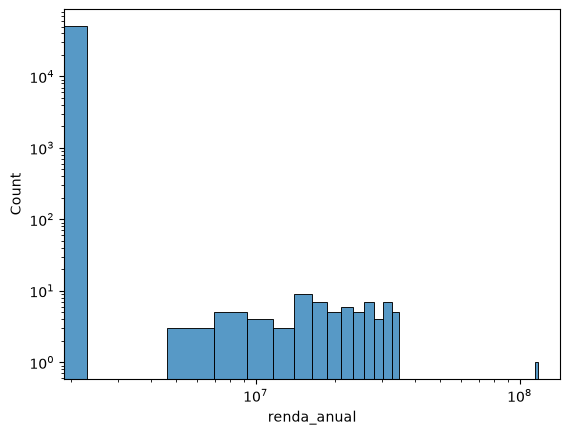

In [324]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(base_cadastral["renda_anual"], bins=50)
plt.yscale("log")
plt.xscale("log")

#### Consolidação da renda declarada e renda para o modelo

O dicionário define `renda_anual` como a renda total anual declarada pelo cliente. A base registra valores negativos, mas a definição não esclarece se eles representam prejuízo, ajuste ou erro cadastral. Por isso, separamos o que foi declarado do valor usado para estimar a capacidade de pagamento.

- `renda_anual` mantém a média dos valores numéricos declarados, incluindo negativos e zero. As declarações individuais podem ser consultadas no Parquet original.
- `renda_negativa` vale 1 quando pelo menos uma declaração do cliente é negativa e 0 nos demais casos. A flag é calculada antes da consolidação, porque a média pode ficar positiva mesmo quando uma das declarações é negativa.
- `renda_anual_para_modelo` usa a média das declarações numéricas não negativas. Se houver apenas uma, usamos esse valor. Zero continua sendo renda declarada válida. Sem uma declaração não negativa, a renda para o modelo fica ausente.

Dos 67 clientes sinalizados, 65 ficam com renda ausente para o modelo e 2 têm outra declaração utilizável. O cadastro não tem data de atualização, então não conseguimos confirmar se essa outra declaração já estava disponível na data do pedido. Para os demais campos, mantemos a primeira linha na ordem do arquivo. Linhas com identificador ausente permanecem individuais.

##### Uso na modelagem de inadimplência

Usaremos `renda_anual_para_modelo` como variável de renda. Se o estimador exigir imputação, ela será ajustada apenas no treino e reaplicada à validação e à submissão. Se criarmos a variável de comprometimento da renda pela parcela, ela será calculada apenas para rendas estritamente positivas.

A flag `renda_negativa` fica disponível para auditoria. Para decidir se ela entra como preditora, compararemos o modelo com e sem a flag na mesma validação temporal e conferiremos quantos clientes sinalizados e quantos casos de inadimplência aparecem em cada período.

In [395]:
renda_declarada = base_cadastral["renda_anual"]
renda_negativa = renda_declarada.lt(0)
base_cadastral["renda_negativa"] = renda_negativa.astype("int8")
base_cadastral["renda_anual_para_modelo"] = renda_declarada.mask(renda_negativa)

cliente_identificado = base_cadastral["id_cliente"].notna()
colunas_renda = ["renda_anual", "renda_anual_para_modelo"]
renda_por_cliente = base_cadastral.loc[cliente_identificado].groupby("id_cliente")
base_cadastral.loc[cliente_identificado, colunas_renda] = renda_por_cliente[colunas_renda].transform("mean")
base_cadastral.loc[cliente_identificado, "renda_negativa"] = renda_por_cliente["renda_negativa"].transform("max")

cadastro_excedente = cliente_identificado & base_cadastral["id_cliente"].duplicated()
base_cadastral = base_cadastral.loc[~cadastro_excedente].copy()

print(f"Cadastros consolidados: {cadastro_excedente.sum()}")
print(f"IDs repetidos após a consolidação: {base_cadastral['id_cliente'].dropna().duplicated().sum()}")
print(f"Clientes com alguma renda negativa declarada: {base_cadastral['renda_negativa'].sum()}")

Cadastros consolidados: 0
IDs repetidos após a consolidação: 0
Clientes com alguma renda negativa declarada: 65


#### Conferência da qualidade após o tratamento cadastral

O resumo apresenta os tipos finais e as ausências por coluna. A checagem entre filhos e membros da família identifica registros para revisão, considerando que o cliente integra a família. Essas relações dependem também da definição de filhos declarados e da composição familiar.


In [ ]:
resumo_qualidade_cadastral = pd.DataFrame({
    "datatype": base_cadastral.dtypes.astype("string"),
    "qtd_nulos": base_cadastral.isna().sum(),
    "percentual_nulos": base_cadastral.isna().mean().mul(100).round(2),
    "valores_distintos": base_cadastral.nunique(),
})
display(resumo_qualidade_cadastral)

familia_para_revisao = (
    base_cadastral["qtd_membros_familia"].notna()
    & base_cadastral["qtd_filhos"].notna()
    & base_cadastral["qtd_membros_familia"].le(base_cadastral["qtd_filhos"])
)
print(f"Registros com membros da família <= quantidade de filhos: {familia_para_revisao.sum()}")
display(base_cadastral.loc[
    familia_para_revisao, ["id_cliente", "qtd_filhos", "qtd_membros_familia"]
].head(10))


### `historico_parcelas`

Cada linha representa um lançamento associado a uma parcela, vinculada ao contrato e ao cliente. Uma mesma parcela e versão pode ter vários lançamentos de pagamento.

| Coluna | Descrição | Tipo de variável | Tipo de dado esperado |
| --- | --- | --- | --- |
| `id_contrato` | Identificador do contrato de empréstimo | Identificador | `int` |
| `id_cliente` | Identificador do cliente | Identificador | `int` |
| `versao_parcela` | Código da versão da parcela | Categórica nominal | `Int64` |
| `numero_parcela` | Número sequencial da parcela dentro do contrato | Numérica discreta | `Int64` |
| `data_prevista_pagamento` | Data prevista para o pagamento da parcela | Temporal | `datetime64[ns]` |
| `data_real_pagamento` | Data registrada do pagamento | Temporal | `datetime64[ns]` |
| `valor_previsto_parcela` | Valor previsto da parcela | Numérica contínua | `float` |
| `valor_pago_parcela` | Valor pago no lançamento | Numérica contínua | `float` |

Os tipos da tabela descrevem o esquema esperado. O código de ingestão e tratamento determina os tipos efetivamente carregados ou convertidos.

Carregamos a base do Parquet original e tratamos as duplicidades. As discussões sobre datas ficam no [registro do tratamento anterior](../tratamento_historico_parcelas_versao_anterior.md).

#### Deduplicação de linhas idênticas

Nesta cópia de teste, preservamos as versões anteriores. Removemos apenas linhas idênticas em todos os campos do Parquet. O cronograma usa a maior versão como referência em uma tabela própria.

In [1]:
chave_parcela = ["id_cliente", "id_contrato", "numero_parcela"]
linhas_originais = len(historico_parcelas)
historico_parcelas = historico_parcelas.drop_duplicates().copy()
print("Linhas idênticas removidas:", linhas_originais - len(historico_parcelas))

#### Conversão das datas de pagamento

Removemos espaços nas extremidades e convertemos as datas no formato `AAAA-MM-DD`. Ausências e valores inválidos ficam como `NaT`, com contagens separadas.

In [2]:
resumo_conversao_datas_parcelas = {}
for coluna in ["data_prevista_pagamento", "data_real_pagamento"]:
    original = historico_parcelas[coluna]
    datas = pd.to_datetime(original.astype("string").str.strip(),
                           format="%Y-%m-%d", errors="coerce").astype("datetime64[ns]")
    falha = original.notna() & datas.isna()
    resumo_conversao_datas_parcelas[coluna] = {
        "Ausentes na origem": original.isna().sum(),
        "Falhas de conversão": falha.sum(),
        "Menor data": datas.min(),
        "Maior data": datas.max(),
    }
    historico_parcelas[coluna] = datas

display(pd.DataFrame(resumo_conversao_datas_parcelas).T)

,Ausentes na origem,Falhas de conversão,Menor data,Maior data
data_prevista_pagamento,0,0,2017-02-28 00:00:00,2025-02-22 00:00:00
data_real_pagamento,3628,0,2017-02-12 00:00:00,2025-02-22 00:00:00


#### Teste de pagamentos parciais entre versões

Comparamos o previsto da maior versão com três totais: o de cada versão isolada, a soma bruta e a soma que trata data real e valor iguais entre versões como possível repetição. Nessa última soma, mantemos a maior multiplicidade observada dentro de uma versão. Datas ausentes ficam fora dessa deduplicação experimental. Comparamos as diferenças em centavos e analisamos pagamentos positivos. A coincidência do total indica compatibilidade com pagamentos parciais. A confirmação depende de um identificador de transação.

In [3]:
chave_versao = [*chave_parcela, "versao_parcela"]
maior_versao = historico_parcelas.groupby(chave_parcela)["versao_parcela"].transform("max")
cronograma_parcelas = (
    historico_parcelas.loc[historico_parcelas["versao_parcela"].eq(maior_versao)]
    .groupby(chave_parcela)
    .agg(versao_referencia=("versao_parcela", "first"),
         valor_previsto=("valor_previsto_parcela", "first"),
         vencimento=("data_prevista_pagamento", "first"),
         valores_previstos_na_versao=("valor_previsto_parcela", "nunique"))
)

lancamentos_pagamentos = historico_parcelas.loc[
    historico_parcelas["valor_pago_parcela"].gt(0)
].copy()
assinatura = [*chave_parcela, "data_real_pagamento", "valor_pago_parcela"]
lancamentos_pagamentos["possivel_repeticao_entre_versoes"] = (
    lancamentos_pagamentos.groupby(assinatura, dropna=False)["versao_parcela"]
    .transform("nunique").gt(1)
    & lancamentos_pagamentos["data_real_pagamento"].notna()
)
# Preservamos a multiplicidade dentro de cada versão, inclusive em caso de empate.
lancamentos_pagamentos["ocorrencia_na_versao"] = (
    lancamentos_pagamentos.groupby([*assinatura, "versao_parcela"], dropna=False).cumcount()
)
pagamentos_sem_repeticao_provavel = lancamentos_pagamentos.loc[
    ~lancamentos_pagamentos["possivel_repeticao_entre_versoes"]
    | ~lancamentos_pagamentos.duplicated([*assinatura, "ocorrencia_na_versao"])
]
por_versao = lancamentos_pagamentos.groupby(chave_versao).agg(
    total_pago=("valor_pago_parcela", "sum"),
    lancamentos=("valor_pago_parcela", "size"),
)
por_versao = por_versao.join(cronograma_parcelas["valor_previsto"], on=chave_parcela)
por_versao["atinge_previsto"] = por_versao["total_pago"].sub(por_versao["valor_previsto"]).round(2).eq(0)
resumo = por_versao.groupby(level=chave_parcela).agg(
    versoes_pagas=("total_pago", "size"),
    alguma_versao_fecha=("atinge_previsto", "any"),
    soma_bruta=("total_pago", "sum"),
    lancamentos=("lancamentos", "sum"),
)
resumo = cronograma_parcelas.join(resumo)
resumo["versoes_pagas"] = resumo["versoes_pagas"].fillna(0).astype(int)
resumo["soma_sem_repeticao_provavel"] = pagamentos_sem_repeticao_provavel.groupby(
    chave_parcela
)["valor_pago_parcela"].sum()
resumo["soma_bruta_fecha"] = resumo["soma_bruta"].sub(resumo["valor_previsto"]).round(2).eq(0)
resumo["soma_sem_repeticao_fecha"] = resumo["soma_sem_repeticao_provavel"].sub(
    resumo["valor_previsto"]
).round(2).eq(0)

multiplas_versoes = resumo.loc[resumo["versoes_pagas"].gt(1)]
uma_versao_fracionada = resumo.loc[resumo["versoes_pagas"].eq(1) & resumo["lancamentos"].gt(1)]
candidatas_parciais_entre_versoes = multiplas_versoes.loc[
    multiplas_versoes["soma_sem_repeticao_fecha"] & ~multiplas_versoes["alguma_versao_fecha"]
]
tabela_teste_versoes = pd.DataFrame({
    "Parcelas": [len(uma_versao_fracionada), len(multiplas_versoes)],
    "Alguma versão sozinha fecha": [
        uma_versao_fracionada["alguma_versao_fecha"].sum(), multiplas_versoes["alguma_versao_fecha"].sum()
    ],
    "Soma bruta de todos os lançamentos fecha": [
        uma_versao_fracionada["soma_bruta_fecha"].sum(), multiplas_versoes["soma_bruta_fecha"].sum()
    ],
    "Soma sem repetição provável fecha": [
        uma_versao_fracionada["soma_sem_repeticao_fecha"].sum(), multiplas_versoes["soma_sem_repeticao_fecha"].sum()
    ],
    "Fecha combinando versões e nenhuma fecha sozinha": [0, len(candidatas_parciais_entre_versoes)],
}, index=["Uma versão paga com vários lançamentos", "Várias versões pagas"])
display(tabela_teste_versoes)
display(candidatas_parciais_entre_versoes)

lancamentos_candidatos = (
    lancamentos_pagamentos.merge(candidatas_parciais_entre_versoes.reset_index()[chave_parcela],
                                 on=chave_parcela, validate="many_to_one")
    .sort_values(chave_versao + ["data_real_pagamento"])
)
display(lancamentos_candidatos.head(20))

,Parcelas,Alguma versão sozinha fecha,Soma bruta de todos os lançamentos fecha,Soma sem repetição provável fecha,Fecha combinando versões e nenhuma fecha sozinha
Uma versão paga com vários lançamentos,72703,67132,67132,67132,0
Várias versões pagas,9973,26,0,0,0


,,,versao_referencia,valor_previsto,vencimento,valores_previstos_na_versao,versoes_pagas,alguma_versao_fecha,soma_bruta,lancamentos,soma_sem_repeticao_provavel,soma_bruta_fecha,soma_sem_repeticao_fecha
id_cliente,id_contrato,numero_parcela,,,,,,,,,,,


,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela,possivel_repeticao_entre_versoes,ocorrencia_na_versao


In [4]:
multiplas = multiplas_versoes.copy()
replicadas = lancamentos_pagamentos.loc[
    lancamentos_pagamentos["possivel_repeticao_entre_versoes"], chave_parcela
].drop_duplicates()
multiplas["assinatura_repetida"] = multiplas.index.isin(pd.MultiIndex.from_frame(replicadas))
previstos_por_versao = historico_parcelas.groupby(chave_versao)["valor_previsto_parcela"].first()
comparacao_por_versao = por_versao.join(previstos_por_versao.rename("previsto_da_versao"))
comparacao_por_versao["fecha_proprio_previsto"] = comparacao_por_versao["total_pago"].sub(
    comparacao_por_versao["previsto_da_versao"]
).round(2).eq(0)
proprio_previsto = comparacao_por_versao.groupby(level=chave_parcela)["fecha_proprio_previsto"].agg(
    alguma="any", todas="all"
).reindex(multiplas.index)
diferenca_combinada = multiplas["soma_sem_repeticao_provavel"].sub(multiplas["valor_previsto"]).round(2)
display(pd.Series({
    "Parcelas com assinatura repetida em versões": multiplas["assinatura_repetida"].sum(),
    "Parcelas sem assinatura repetida em versões": (~multiplas["assinatura_repetida"]).sum(),
    "Combinação abaixo do previsto da maior versão": diferenca_combinada.lt(0).sum(),
    "Combinação acima do previsto da maior versão": diferenca_combinada.gt(0).sum(),
    "Alguma versão paga fecha seu próprio previsto": proprio_previsto["alguma"].sum(),
    "Todas as versões pagas fecham seus próprios previstos": proprio_previsto["todas"].sum(),
}).to_frame("parcelas"))

,parcelas
Parcelas com assinatura repetida em versões,9826
Parcelas sem assinatura repetida em versões,147
Combinação abaixo do previsto da maior versão,0
Combinação acima do previsto da maior versão,9973
Alguma versão paga fecha seu próprio previsto,31
Todas as versões pagas fecham seus próprios previstos,26


#### Resultado da comparação

Das 9.973 parcelas com pagamentos positivos em várias versões, nenhuma fechou o previsto da maior versão ao somar todos os lançamentos, com ou sem o ajuste de possíveis repetições. Em 26, pelo menos uma versão isolada fechou esse previsto. Entre as 72.703 parcelas com uma versão paga e vários lançamentos, 67.132 fecharam o previsto de referência.

O teste combina todos os lançamentos distintos de cada parcela. Ele não procura subconjuntos de valores nem confirma a identidade de transações sem um identificador. O notebook principal permanece com o tratamento vigente.

### `historico_emprestimos`

Cada linha representa um contrato anterior vinculado a um cliente, identificado pelo par (`id_cliente`, `id_contrato`).

Coluna|Descricao|Tipo de variável|Datatype provável|
|-|-|-|-|
|`id_contrato`|Identificador único do contrato de empréstimo| identificador numérico |int|
|`id_cliente`|Identificador do cliente associado ao contrato| identificador numérico |int|
|`tipo_contrato`|Tipo de contrato|Categórica nominal|str|
|`status_contrato`|Status final do contrato (aprovado, recusado, etc.)|Categórica nominal|str|
|`data_decisao`|Data em que o contrato foi analisado e aprovado ou recusado|Temporal (data)|datetime64[ns]|
|`data_liberacao`|Data em que o crédito foi liberado|Temporal (data)|datetime64[ns]|
|`data_primeiro_vencimento`|Data prevista para o vencimento da primeira parcela|Temporal (data)|datetime64[ns]|
|`data_ultimo_vencimento_original`|Data original prevista para a última parcela|Temporal (data)|datetime64[ns]|
|`data_ultimo_vencimento`|Data final revisada da última parcela|Temporal (data)|datetime64[ns]|
|`data_encerramento`|Data em que o contrato foi encerrado (por quitação, cancelamento, etc.)|Temporal (data)|datetime64[ns]|
|`valor_solicitado`|Valor inicialmente solicitado pelo cliente|Numérica contínua|float|
|`valor_credito`|Valor efetivamente liberado|Numérica contínua|float|
|`valor_bem`|Valor do bem adquirido, quando aplicável|Numérica contínua|float|
|`valor_parcela`|Valor estimado da parcela periódica|Numérica contínua|float|
|`valor_entrada`|Valor pago como entrada|Numérica contínua|float|
|`percentual_entrada`|Percentual da entrada sobre o valor total|Numérica contínua|float|
|`qtd_parcelas_planejadas`|Quantidade de parcelas previstas no contrato|Numérica discreta|Int64 (aceita ausentes)|
|`taxa_juros_padrao`|Taxa de juros padrão aplicada|Numérica contínua|float|
|`taxa_juros_promocional`|Taxa promocional (se aplicável)|Numérica contínua|float|
|`tipo_pagamento`|Forma de pagamento do contrato|Categórica nominal|str|
|`finalidade_emprestimo`|Finalidade declarada para o uso do empréstimo|Categórica nominal|str|
|`tipo_cliente`|Tipo de cliente (novo, recorrente, etc.)|Categórica nominal|str|
|`faixa_rendimento`|Categoria de retorno do cliente para o banco|Categórica nominal|str|
|`tipo_portfolio`|Tipo de portfólio (interno, externo, etc.)|Categórica nominal|str|
|`tipo_produto`|Tipo de produto financeiro contratado|Categórica nominal|str|
|`categoria_bem`|Categoria do bem financiado|Categórica nominal|str|
|`combinacao_produto`|Combinação de produtos oferecida|Categórica nominal|str|
|`setor_vendedor`|Setor da empresa vendedora|Categórica nominal|str|
|`canal_venda`|Canal utilizado para originação da venda|Categórica nominal|str|
|`area_venda`|Área ou localização da venda|Categórica nominal|str|
|`dia_semana_solicitacao`|Dia da semana em que a solicitação foi iniciada|Categórica nominal|str|
|`hora_solicitacao`|Hora do dia em que a solicitação foi iniciada|Temporal (horário do dia)|string (`HH:MM:SS`)|
|`indicador_ultima_solicitacao_contrato`|Indica se foi a última solicitação para aquele contrato|Categórica binária|Int64 (0/1, aceita ausentes)|
|`indicador_ultima_solicitacao_dia`|Indica se foi a última solicitação feita no mesmo dia|Categórica binária|Int64 (0/1, aceita ausentes)|
|`motivo_recusa`|Motivo da recusa, quando o contrato foi negado|Categórica nominal|str|
|`acompanhantes_cliente`|Tipo de acompanhantes no momento da solicitação (ex: sozinho, família)|Categórica nominal|str|
|`indicador_seguro_contratado`|Indica se o cliente contratou seguro junto com o crédito|Categórica binária|Int64 (0/1, aceita ausentes)|

Os datatypes indicam os tipos esperados após o tratamento inicial. `Int64` permite representar inteiros com valores ausentes.

`hora_solicitacao` contém horários no formato `HH:MM:SS`. O tipo `string` preserva a exibição do horário. `dia_semana_solicitacao` é uma categoria com comportamento cíclico.

O dicionário nomeia os três indicadores com o prefixo `flag_`. A tabela acima utiliza os nomes presentes no arquivo Parquet, com o prefixo `indicador_`. `faixa_rendimento` é mantida como nominal porque as classes apresentam perfis distintos sem uma ordem de retorno confirmada. `area_venda` é representada como texto, preservando todos os valores.

#### Critérios do tratamento inicial de empréstimos

As etapas seguem a ordem binárias, datetime, categóricas ordinais, categóricas nominais, inteiras e float. Cada coluna aparece no grupo do seu tipo final. Textos são padronizados em minúsculas e `nao informado` permanece como texto, exceto em `faixa_rendimento`, onde foi definida sua conversão para nulo. Nulos originais são preservados.

As datas são convertidas sem preenchimento por outra data e sem alteração da cronologia. A escolha de datas de referência fica no tópico de definição das bases. Valores monetários, taxas e percentuais já chegam como `float64`; suas escalas, zeros e nulos são mantidos. Identificadores já inteiros recebem somente validação de positividade. As decisões sem definição de negócio ficam explicitamente indicadas nas respectivas colunas.

In [329]:
historico_emprestimos[historico_emprestimos["status_contrato"] == "cancelado"].groupby("motivo_recusa").size().sort_values(ascending=False).head(10).rename("quantidade de contratos cancelados").to_frame()

,quantidade de contratos cancelados
motivo_recusa,


In [330]:
historico_emprestimos["status_contrato"].value_counts(dropna=False)

status_contrato
Aprovado                131735
Cancelado                40266
Recusado                 36359
Oferta não utilizada      3584
Name: count, dtype: int64

#### Colunas Binárias

##### `indicador_ultima_solicitacao_contrato`

Padronizamos `Sim` como `1` e `Não` como `0`.

In [331]:
historico_emprestimos["indicador_ultima_solicitacao_contrato"] = (
    historico_emprestimos["indicador_ultima_solicitacao_contrato"]
    .astype("string").str.strip().str.lower()
    .map({"sim": 1, "não": 0, "nao": 0, "1": 1, "0": 0})
    .astype("Int64")
)
display(historico_emprestimos["indicador_ultima_solicitacao_contrato"].value_counts(dropna=False))

indicador_ultima_solicitacao_contrato
1    210894
0      1050
Name: count, dtype: Int64

##### `indicador_ultima_solicitacao_dia`

A coluna já chega como `int64` com valores `0` e `1`. Mantemos a codificação e o tipo existentes.

In [332]:
display(historico_emprestimos["indicador_ultima_solicitacao_dia"].value_counts(dropna=False))

indicador_ultima_solicitacao_dia
1    211238
0       706
Name: count, dtype: int64

##### `indicador_seguro_contratado`

A coluna chega como `float64` com `0`, `1` e nulos. Convertemos para `Int64`, preservando as ausências. Ausência de informação não é preenchida como ausência de seguro.

In [333]:
historico_emprestimos["indicador_seguro_contratado"] = (
    historico_emprestimos["indicador_seguro_contratado"].astype("Int64")
)
display(historico_emprestimos["indicador_seguro_contratado"].value_counts(dropna=False))

indicador_seguro_contratado
<NA>    85165
0       84864
1       41915
Name: count, dtype: Int64

#### Datetime

As datas preenchidas observadas estão no formato `AAAA-MM-DD`. `errors="coerce"` representa falhas de conversão como `NaT`, mantendo também as ausências originais. Todas as datas preenchidas na fonte atual são conversíveis. 

##### `data_decisao`

Data de decisão do contrato. Sua presença também pode ocorrer em contratos recusados ou cancelados.

In [334]:
historico_emprestimos["data_decisao"] = pd.to_datetime(
    historico_emprestimos["data_decisao"], format="%Y-%m-%d", errors="coerce"
)
display(historico_emprestimos["data_decisao"].agg(["min", "max", "count"]))
print(f'n° nulos: {historico_emprestimos["data_decisao"].isna().sum()}')

min      2017-02-04 00:00:00
max      2025-03-09 00:00:00
count                 211944
Name: data_decisao, dtype: object

n° nulos: 0


##### `data_liberacao`

Data informada de liberação do crédito. Mantemos as ausências para discutir a referência temporal na etapa de construção das bases.

In [335]:
historico_emprestimos["data_liberacao"] = pd.to_datetime(
    historico_emprestimos["data_liberacao"], format="%Y-%m-%d", errors="coerce"
)
display(historico_emprestimos["data_liberacao"].agg(["min", "max", "count"]))
print(f'n° nulos: {historico_emprestimos["data_liberacao"].isna().sum()}')

min      2017-02-13 00:00:00
max      2025-02-21 00:00:00
count                   7709
Name: data_liberacao, dtype: object

n° nulos: 204235


##### `data_primeiro_vencimento`

Vencimento previsto da primeira parcela.

In [336]:
historico_emprestimos["data_primeiro_vencimento"] = pd.to_datetime(
    historico_emprestimos["data_primeiro_vencimento"], format="%Y-%m-%d", errors="coerce"
)
display(historico_emprestimos["data_primeiro_vencimento"].agg(["min", "max", "count"]))

min      2017-03-03 00:00:00
max      2025-03-14 00:00:00
count                 122712
Name: data_primeiro_vencimento, dtype: object

##### `data_ultimo_vencimento_original`

Vencimento original da última parcela. Datas futuras podem corresponder ao cronograma planejado.

In [337]:
historico_emprestimos["data_ultimo_vencimento_original"] = pd.to_datetime(
    historico_emprestimos["data_ultimo_vencimento_original"], format="%Y-%m-%d", errors="coerce"
)
display(historico_emprestimos["data_ultimo_vencimento_original"].agg(["min", "max", "count"]))

min      2017-06-08 00:00:00
max      2031-08-21 00:00:00
count                 116696
Name: data_ultimo_vencimento_original, dtype: object

##### `data_ultimo_vencimento`

Vencimento final revisado registrado no histórico.

In [338]:
historico_emprestimos["data_ultimo_vencimento"] = pd.to_datetime(
    historico_emprestimos["data_ultimo_vencimento"], format="%Y-%m-%d", errors="coerce"
)
display(historico_emprestimos["data_ultimo_vencimento"].agg(["min", "max", "count"]))

min      2017-04-01 00:00:00
max      2025-02-21 00:00:00
count                  96816
Name: data_ultimo_vencimento, dtype: object

##### `data_encerramento`

Data de encerramento registrada. Relações cronológicas inconsistentes serão apresentadas para revisão.

In [339]:
historico_emprestimos["data_encerramento"] = pd.to_datetime(
    historico_emprestimos["data_encerramento"], format="%Y-%m-%d", errors="coerce"
)
display(historico_emprestimos["data_encerramento"].agg(["min", "max", "count"]))

min      2016-01-01 00:00:00
max      2025-03-03 00:00:00
count                  95183
Name: data_encerramento, dtype: object

##### `hora_solicitacao`

Mantemos o horário como texto no formato `HH:MM:SS`. Valores fora de `00:00:00` a `23:59:59` ficam ausentes.

In [340]:
def padronizar_hora_solicitacao(valores):
    horarios = valores.astype("string").str.strip()
    horarios_validos = horarios.str.fullmatch(r"(?:[01][0-9]|2[0-3]):[0-5][0-9]:[0-5][0-9]", na=False)
    return horarios.where(horarios_validos)


hora_original = historico_emprestimos["hora_solicitacao"]
historico_emprestimos["hora_solicitacao"] = padronizar_hora_solicitacao(hora_original)
display(historico_emprestimos["hora_solicitacao"].describe())
print("Horários inválidos:", (hora_original.notna() & historico_emprestimos["hora_solicitacao"].isna()).sum())

count       211944
unique       51388
top       10:48:32
freq            18
Name: hora_solicitacao, dtype: object

Horários inválidos: 0


#### Categóricas Ordinais

Nenhuma coluna com ordem confirmada para conversão nesta etapa. `faixa_rendimento` é tratada como categórica nominal na seção seguinte.

#### Categóricas Nominais (texto)

Convertemos para `string`, removemos espaços nas extremidades, reduzimos espaços consecutivos e padronizamos minúsculas. `Não informado` e suas variações ficam como `nao informado`. Nulos originais e rótulos de significado distinto, como `não se aplica`, são mantidos. Não agrupamos categorias por suposição de equivalência de negócio.

##### `tipo_contrato`

Unificamos também as grafias `emprestimo em dinheiro` e `credito rotativo` com as categorias acentuadas correspondentes.

In [341]:
historico_emprestimos["tipo_contrato"] = (
    historico_emprestimos["tipo_contrato"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
    .replace({"emprestimo em dinheiro": "empréstimo em dinheiro", "credito rotativo": "crédito rotativo"})
)

display(historico_emprestimos["tipo_contrato"].value_counts(dropna=False))

tipo_contrato
empréstimo em dinheiro      80503
financiamento de consumo    78391
crédito rotativo            53050
Name: count, dtype: int64[pyarrow]

##### `status_contrato`

Preservamos os status distintos. Nenhum status é usado para excluir contratos nesta etapa.

In [342]:
historico_emprestimos["status_contrato"] = (
    historico_emprestimos["status_contrato"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
)

display(historico_emprestimos["status_contrato"].value_counts(dropna=False))

status_contrato
aprovado                131735
cancelado                40266
recusado                 36359
oferta não utilizada      3584
Name: count, dtype: int64[pyarrow]

##### `tipo_pagamento`

Padronizamos as formas de pagamento e preservamos o marcador de informação ausente como texto.

In [343]:
historico_emprestimos["tipo_pagamento"] = (
    historico_emprestimos["tipo_pagamento"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["tipo_pagamento"].value_counts(dropna=False))

tipo_pagamento
dinheiro pelo banco              130983
nao informado                     79757
débito em conta do cliente         1031
débito em conta do empregador       173
Name: count, dtype: int64[pyarrow]

##### `finalidade_emprestimo`

Preservamos as finalidades e as categorias `não se aplica`, `nao informado` e `cliente não informou a finalidade` como rótulos distintos.

In [344]:
historico_emprestimos["finalidade_emprestimo"] = (
    historico_emprestimos["finalidade_emprestimo"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado",
              "cliente não informou a finalidade": "nao informado"})
)

display(historico_emprestimos["finalidade_emprestimo"].value_counts(dropna=False))

finalidade_emprestimo
não se aplica                          117244
nao informado                           85953
reformas                                 2944
outro                                    1894
necessidades urgentes                    1082
compra de carro usado                     383
construção de casa ou anexo               341
despesas do dia a dia                     320
saúde                                     296
pagamento de outros empréstimos           250
educação                                  197
compra de eletrônicos                     165
viagem                                    134
casamento, presente ou feriado            130
compra de carro novo                      122
reparo de veículo                         100
móveis                                     94
compra de imóvel                           94
compra de casa de férias ou terreno        79
desenvolvimento do negócio                 61
gás ou abastecimento de água               37
compra de ga

##### `tipo_cliente`

Padronizamos as categorias de cliente.

In [345]:
historico_emprestimos["tipo_cliente"] = (
    historico_emprestimos["tipo_cliente"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["tipo_cliente"].value_counts(dropna=False))

tipo_cliente
recorrente       156066
novo              38463
reativado         17163
nao informado       252
Name: count, dtype: int64[pyarrow]

##### `faixa_rendimento`

Mantemos as quatro classes como **categóricas nominais**, no dtype `string`, com rótulos distintos e sem ordenação. `Não informado` e `nao informado` são convertidos em nulos, conforme definido para esta coluna.

A comparação de `valor_credito` abaixo mostra que `média` e `alta` têm créditos menores que as duas classes baixas. As medianas são R$ 146.596,50 em `baixa ação`, R$ 168.682,50 em `baixa normal`, R$ 130.699,48 em `média` e R$ 60.567,75 em `alta`. As respectivas médias são R$ 402.978,71, R$ 381.385,80, R$ 234.319,69 e R$ 114.325,55. Entre as duas classes baixas, média e mediana indicam ordens opostas, e as distribuições se cruzam.

Também há diferenças comerciais entre os subtipos. `Ponto de venda casa sem juros` representa 46,41% de `baixa ação` e 5,14% de `baixa normal`, e a mediana de parcelas planejadas é 24 contra 12. Isso é compatível com condições comerciais distintas, incluindo possíveis campanhas promocionais, cujo significado precisa ser confirmado. Como a coluna descreve retorno para o banco e os valores de crédito não estabelecem sua hierarquia, preservamos as classes sem impor uma escala ordinal.


In [346]:
historico_emprestimos["faixa_rendimento"] = (
    historico_emprestimos["faixa_rendimento"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": pd.NA, "nao informado": pd.NA})
)

display(historico_emprestimos["faixa_rendimento"].value_counts(dropna=False))

faixa_rendimento
<NA>            65804
média           48626
alta            44862
baixa normal    40811
baixa ação      11841
Name: count, dtype: int64[pyarrow]

In [347]:
resumo_credito_por_faixa = (
    historico_emprestimos.groupby("faixa_rendimento", dropna=False)["valor_credito"]
    .agg(qtd_contratos="size", mediana="median", media="mean", minimo="min", maximo="max")
)
display(resumo_credito_por_faixa)

,qtd_contratos,mediana,media,minimo,maximo
faixa_rendimento,,,,,
alta,44862,60567.75,114325.549188,0.0,1265850.0
baixa ação,11841,146596.50,402978.710104,0.0,3749053.5
baixa normal,40811,168682.50,381385.800583,0.0,3701943.0
média,48626,130699.48,234319.692454,6984.0,1862802.0
<NA>,65804,0.00,70633.374917,0.0,2874087.0


##### `tipo_portfolio`

Padronizamos os portfólios, preservando as categorias existentes.

In [348]:
historico_emprestimos["tipo_portfolio"] = (
    historico_emprestimos["tipo_portfolio"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["tipo_portfolio"].value_counts(dropna=False))

tipo_portfolio
cartões           66867
ponto de venda    65808
dinheiro          43738
nao informado     35485
veículos             46
Name: count, dtype: int64[pyarrow]

##### `tipo_produto`

Padronizamos os produtos e preservamos a informação de ausência como texto.

In [349]:
historico_emprestimos["tipo_produto"] = (
    historico_emprestimos["tipo_produto"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["tipo_produto"].value_counts(dropna=False))

tipo_produto
nao informado             135339
venda cruzada              57430
atendimento espontâneo     19175
Name: count, dtype: int64[pyarrow]

##### `categoria_bem`

Padronizamos as categorias de bens sem agrupar setores nesta etapa.

In [350]:
historico_emprestimos["categoria_bem"] = (
    historico_emprestimos["categoria_bem"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["categoria_bem"].value_counts(dropna=False))

categoria_bem
nao informado                 98847
celular                       30338
eletrônicos de consumo        20566
computadores                  18743
áudio e vídeo                 18366
móveis                        14113
foto e cinema                  2403
materiais de construção        2392
roupas e acessórios            2262
acessórios automotivos          746
joias                           577
artigos para casa               492
suprimentos médicos             384
veículos                        312
jardinagem                      277
esporte e lazer                 277
outro                           273
equipamentos de escritório      222
turismo                         134
saúde                           125
venda direta                     33
atividade física                 29
serviço adicional                18
arma                              9
educação                          3
seguro                            3
Name: count, dtype: int64[pyarrow]

##### `combinacao_produto`

Preservamos os componentes dos rótulos e os nulos originais.

In [351]:
historico_emprestimos["combinacao_produto"] = (
    historico_emprestimos["combinacao_produto"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["combinacao_produto"].value_counts(dropna=False))

combinacao_produto
cartão captação externa               37301
cartão venda cruzada                  34120
dinheiro                              27453
ponto de venda casa com juros         24794
ponto de venda celular com juros      20987
dinheiro venda cruzada: média         13567
dinheiro venda cruzada: low           12189
ponto de venda indústria com juros     9441
ponto de venda casa sem juros          8075
dinheiro captação externa: alta        5832
dinheiro venda cruzada: alta           5687
dinheiro captação externa: média       3258
dinheiro captação externa: low         3205
ponto de venda celular sem juros       2335
ponto de venda outros com juros        2180
ponto de venda indústria sem juros     1249
ponto de venda outros sem juros         244
<NA>                                     27
Name: count, dtype: int64[pyarrow]

##### `setor_vendedor`

Padronizamos os setores existentes.

In [352]:
historico_emprestimos["setor_vendedor"] = (
    historico_emprestimos["setor_vendedor"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["setor_vendedor"].value_counts(dropna=False))

setor_vendedor
nao informado                108594
eletrônicos de consumo        50757
conectividade                 34767
móveis                         7458
construção                     3827
vestuário                      3029
indústria                      2425
tecnologia automotiva           596
joias                           308
parceiros de venda direta       142
turismo                          41
Name: count, dtype: int64[pyarrow]

##### `canal_venda`

Padronizamos os canais de venda existentes.

In [353]:
historico_emprestimos["canal_venda"] = (
    historico_emprestimos["canal_venda"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["canal_venda"].value_counts(dropna=False))

canal_venda
agências de crédito e dinheiro    91118
rede nacional                     62653
loja física                       26962
regional ou local                 13829
central de atendimento             9004
canal parceiro de empréstimo       7527
canal de vendas corporativas        793
concessionária                       58
Name: count, dtype: int64[pyarrow]

##### `area_venda`

Convertida de `int64` para `string`, preservando todos os valores como rótulos, inclusive `-1`. A conversão foi definida para tratar a coluna como categoria nominal, sem inferir significado para seus códigos.


In [354]:
historico_emprestimos["area_venda"] = historico_emprestimos["area_venda"].astype("string")

display(historico_emprestimos["area_venda"].value_counts(dropna=False))

area_venda
-1      96533
0        7635
50       4806
20       4253
30       4240
        ...  
5286        1
882         1
966         1
1633        1
562         1
Name: count, Length: 1614, dtype: int64[pyarrow]

##### `dia_semana_solicitacao`

Mantemos os nomes dos dias como texto; o comportamento cíclico poderá ser considerado na criação de features.

In [355]:
historico_emprestimos["dia_semana_solicitacao"] = (
    historico_emprestimos["dia_semana_solicitacao"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["dia_semana_solicitacao"].value_counts(dropna=False))

dia_semana_solicitacao
terça-feira      32277
sexta-feira      32025
quarta-feira     32000
segunda-feira    31898
quinta-feira     30974
sábado           30460
domingo          22310
Name: count, dtype: int64[pyarrow]

##### `motivo_recusa`

Preservamos os motivos, `não se aplica` e `nao informado` como informações distintas.

In [356]:
historico_emprestimos["motivo_recusa"] = (
    historico_emprestimos["motivo_recusa"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["motivo_recusa"].value_counts(dropna=False))

motivo_recusa
não se aplica             167501
histórico de crédito       21667
limite excedido             8597
pontuação baixa             6627
desistência do cliente      5204
pontuação antifraude        1332
nao informado                522
verificação cadastral        406
erro de sistema               88
Name: count, dtype: int64[pyarrow]

##### `acompanhantes_cliente`

Preservamos os nulos originais. Um nulo não é interpretado como cliente desacompanhado.

In [357]:
historico_emprestimos["acompanhantes_cliente"] = (
    historico_emprestimos["acompanhantes_cliente"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
)

display(historico_emprestimos["acompanhantes_cliente"].value_counts(dropna=False))

acompanhantes_cliente
<NA>                   104383
desacompanhado          64324
família                 26972
cônjuge ou parceiro      8608
filhos                   4034
outro b                  2193
outro a                  1147
grupo de pessoas          283
Name: count, dtype: int64[pyarrow]

#### Numéricas Inteiras

##### `id_contrato`

A coluna já é lida como `int64`. Validamos somente a positividade dos identificadores; valores fora desse domínio ficam ausentes. A fonte atual possui apenas identificadores positivos. O mesmo cliente pode ter vários contratos.

In [358]:
historico_emprestimos["id_contrato"] = historico_emprestimos["id_contrato"].where(historico_emprestimos["id_contrato"].gt(0))
display(historico_emprestimos["id_contrato"].agg(["count", "nunique", "min", "max"]))

count       211944
nunique     211944
min        1000003
max        2870416
Name: id_contrato, dtype: int64

In [359]:
historico_emprestimos

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,...,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
0,2802425,108129,empréstimo em dinheiro,aprovado,2024-08-29,NaT,2024-09-28,2027-08-14,NaT,NaT,...,nao informado,central de atendimento,-1,quinta-feira,11:05:09,1,1,não se aplica,desacompanhado,1
1,2330894,258628,crédito rotativo,aprovado,2022-10-11,NaT,2022-11-10,2024-09-30,2024-08-01,2024-08-04,...,nao informado,agências de crédito e dinheiro,-1,terça-feira,15:46:56,1,1,não se aplica,desacompanhado,1
2,1182516,267782,crédito rotativo,aprovado,2023-04-08,NaT,2023-05-08,2025-09-24,NaT,NaT,...,nao informado,agências de crédito e dinheiro,-1,sábado,04:39:38,1,1,não se aplica,<NA>,1
3,1543131,275707,crédito rotativo,aprovado,2024-02-08,NaT,2024-03-09,2025-02-02,2025-02-02,2025-02-09,...,nao informado,agências de crédito e dinheiro,-1,quinta-feira,08:26:26,1,1,não se aplica,desacompanhado,1
4,2261993,299391,empréstimo em dinheiro,cancelado,2024-09-06,NaT,NaT,NaT,NaT,NaT,...,nao informado,agências de crédito e dinheiro,-1,sexta-feira,13:25:16,1,1,não se aplica,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211939,2870412,466247,empréstimo em dinheiro,aprovado,2022-01-21,NaT,2022-03-01,2022-11-26,2022-11-26,2022-11-26,...,nao informado,central de atendimento,-1,sexta-feira,14:37:57,1,1,não se aplica,<NA>,<NA>
211940,2870413,466247,empréstimo em dinheiro,recusado,2024-11-25,NaT,NaT,NaT,NaT,NaT,...,eletrônicos de consumo,rede nacional,507,domingo,15:26:09,1,1,pontuação baixa,cônjuge ou parceiro,1
211941,2870414,466248,financiamento de consumo,recusado,2024-08-08,NaT,NaT,NaT,NaT,NaT,...,nao informado,agências de crédito e dinheiro,-1,terça-feira,14:26:50,1,1,desistência do cliente,desacompanhado,1
211942,2870415,466248,empréstimo em dinheiro,aprovado,2024-11-17,NaT,2024-12-15,2025-11-10,2025-01-27,2025-02-01,...,nao informado,agências de crédito e dinheiro,-1,domingo,15:47:45,1,1,não se aplica,<NA>,<NA>


##### `id_cliente`

A coluna já é lida como `int64`. Validamos somente a positividade dos identificadores; valores fora desse domínio ficam ausentes. A fonte atual possui apenas identificadores positivos. O mesmo cliente pode ter vários contratos.

In [360]:
historico_emprestimos["id_cliente"] = historico_emprestimos["id_cliente"].where(
    historico_emprestimos["id_cliente"].gt(0)
)
display(historico_emprestimos["id_cliente"].agg(["count", "nunique", "min", "max"]))

count      211944
nunique     47952
min        100023
max        466248
Name: id_cliente, dtype: int64

##### `qtd_parcelas_planejadas`

A fonte contém contagens representadas como `float64`, com nulos. Convertemos para `Int64` para manter a quantidade como inteiro e preservar as ausências. Os zeros existentes são mantidos para análise por produto e status.

In [361]:
historico_emprestimos["qtd_parcelas_planejadas"] = (
    historico_emprestimos["qtd_parcelas_planejadas"].astype("Int64")
)
display(historico_emprestimos["qtd_parcelas_planejadas"].value_counts(dropna=False).sort_index())

qtd_parcelas_planejadas
0       16183
3         123
4        3016
5         431
6       22262
7         155
8        3383
9         158
10      17000
11         77
12      38552
13          9
14        935
15         91
16        613
17          5
18      10548
19          1
20        207
22          4
23          9
24      19031
29          2
30       3277
32          1
35          2
36      10497
42        801
46          2
47          1
48       6486
54        231
59          1
60       6561
66          1
72         16
84          8
<NA>    51264
Name: count, dtype: Int64

#### Numéricas float

As oito colunas abaixo já chegam como `float64`. Na fonte atual, seus valores preenchidos são não negativos. Mantemos os valores, zeros e nulos, e apresentamos o resumo de cada coluna. Não há conversão textual necessária nem preenchimento de ausências nesta etapa.

Taxas e percentuais mantêm a escala recebida. Sua unidade e periodicidade precisam estar definidas antes de cálculos financeiros ou comparações entre produtos.

##### `valor_solicitado`

Valor solicitado registrado para o contrato.

count    2.119440e+05
mean     1.763795e+05
std      2.924893e+05
min      0.000000e+00
25%      1.889550e+04
50%      7.182000e+04
75%      1.845000e+05
max      3.825000e+06
Name: valor_solicitado, dtype: float64

<Axes: >

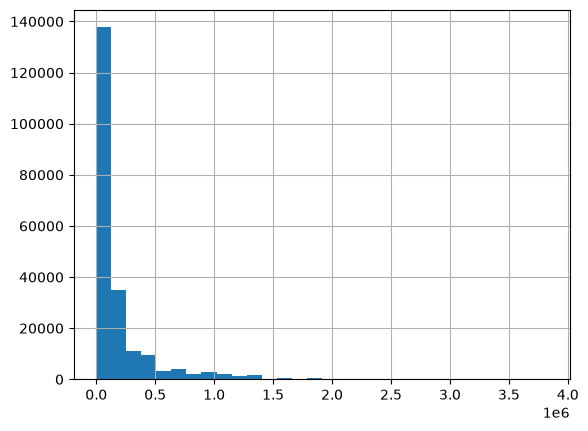

In [362]:
import matplotlib.pyplot as plt

display(historico_emprestimos["valor_solicitado"].describe())
historico_emprestimos["valor_solicitado"].hist(bins=30)

##### `valor_credito`

Valor do crédito registrado. A associação com a base de submissão permanece conforme o planejamento ao final do notebook.

count    2.119440e+05
mean     1.958407e+05
std      3.169973e+05
min      0.000000e+00
25%      2.366100e+04
50%      8.036990e+04
75%      2.159512e+05
max      3.749054e+06
Name: valor_credito, dtype: float64

<Axes: >

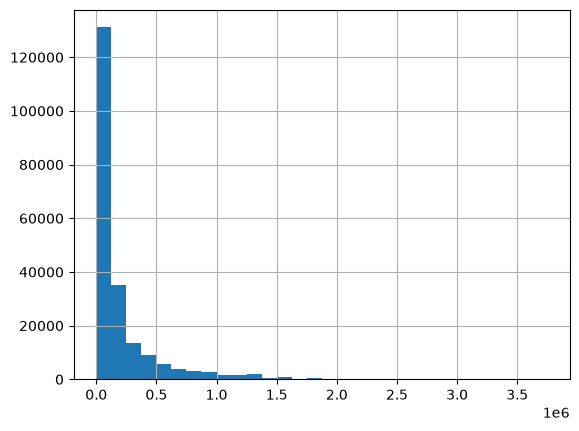

In [363]:
display(historico_emprestimos["valor_credito"].describe())
historico_emprestimos["valor_credito"].hist(bins=30)

##### `valor_bem`

Valor do bem, com ausências preservadas.

count    1.621600e+05
mean     2.236400e+05
std      3.138643e+05
min      0.000000e+00
25%      4.743000e+04
50%      1.078163e+05
75%      2.295000e+05
max      3.825000e+06
Name: valor_bem, dtype: float64

<Axes: >

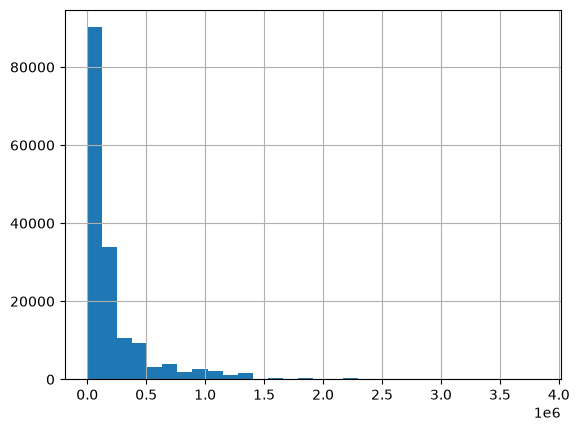

In [364]:
display(historico_emprestimos["valor_bem"].describe())
historico_emprestimos["valor_bem"].hist(bins=30)

##### `valor_parcela`

Valor estimado da parcela, com zeros e ausências preservados.

count    160679.000000
mean      15802.401398
std       16998.124061
min           0.000000
25%        5707.845000
50%       10777.275000
75%       20222.932500
max      474981.770000
Name: valor_parcela, dtype: float64

<Axes: >

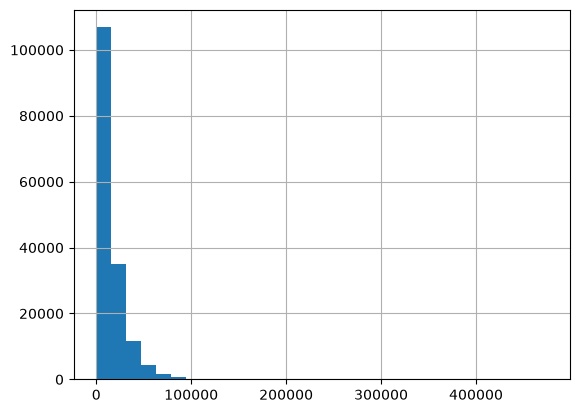

In [365]:
display(historico_emprestimos["valor_parcela"].describe())
historico_emprestimos["valor_parcela"].hist(bins=30)

##### `valor_entrada`

Valor de entrada. Zero e ausência permanecem distinguíveis.

count    9.832600e+04
mean     6.750599e+03
std      2.017729e+04
min      0.000000e+00
25%      0.000000e+00
50%      1.578105e+03
75%      7.789500e+03
max      1.344510e+06
Name: valor_entrada, dtype: float64

<Axes: >

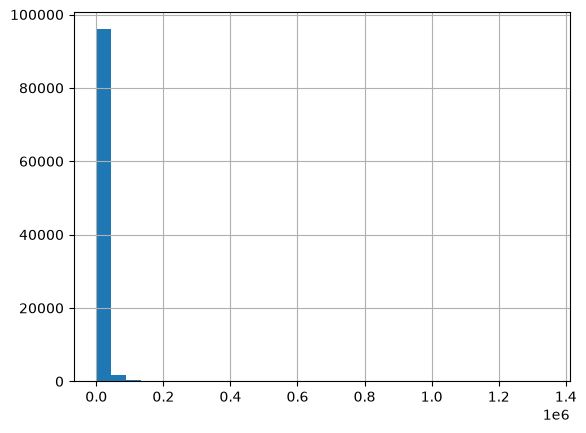

In [366]:
display(historico_emprestimos["valor_entrada"].describe())
historico_emprestimos["valor_entrada"].hist(bins=30)

##### `percentual_entrada`

Percentual registrado na escala original; não multiplicamos por 100.

count    98326.000000
mean         0.080110
std          0.108777
min          0.000000
25%          0.000000
50%          0.050661
75%          0.108912
max          0.989740
Name: percentual_entrada, dtype: float64

<Axes: >

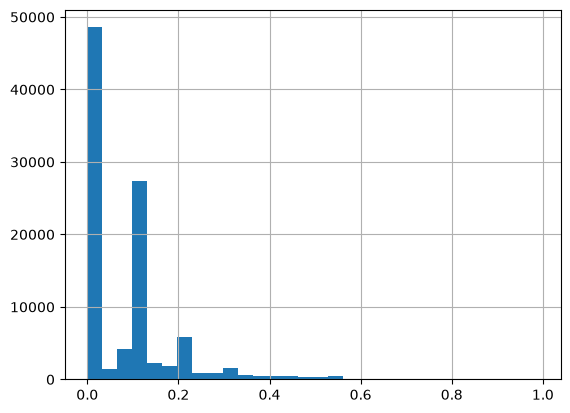

In [367]:
display(historico_emprestimos["percentual_entrada"].describe())
historico_emprestimos["percentual_entrada"].hist(bins=30)


##### `taxa_juros_padrao`

Taxa registrada, com a escala original e a elevada ausência de informação preservadas.

In [368]:
display(historico_emprestimos["taxa_juros_padrao"].describe())

count    711.000000
mean       0.184546
std        0.078294
min        0.059121
25%        0.160702
50%        0.189122
75%        0.193330
max        0.797447
Name: taxa_juros_padrao, dtype: float64

##### `taxa_juros_promocional`

Taxa promocional na escala original, sem inferir unidade ou periodicidade.

In [369]:
display(historico_emprestimos["taxa_juros_promocional"].describe())

count    711.000000
mean       0.774130
std        0.103323
min        0.424419
25%        0.715645
50%        0.835095
75%        0.852537
max        1.000000
Name: taxa_juros_promocional, dtype: float64

#### Conferência da qualidade após o tratamento de empréstimos

Conferimos tipos, ausências, chaves e relações entre datas. As contagens cronológicas apenas identificam registros para discussão. Não substituímos datas, não removemos contratos e não preenchemos `data_liberacao` nesta etapa.

In [370]:
resumo_qualidade_emprestimos = pd.DataFrame({
    "datatype": historico_emprestimos.dtypes.astype("string"),
    "qtd_nulos": historico_emprestimos.isna().sum(),
    "percentual_nulos": historico_emprestimos.isna().mean().mul(100).round(2),
    "valores_distintos": historico_emprestimos.nunique()
})
display(resumo_qualidade_emprestimos)
display(pd.Series({
    "Chaves cliente-contrato repetidas além da primeira": historico_emprestimos.duplicated(["id_cliente", "id_contrato"]).sum(),
    "Liberação anterior à decisão": (historico_emprestimos["data_liberacao"] < historico_emprestimos["data_decisao"]).sum(),
    "Liberação posterior à decisão": (historico_emprestimos["data_liberacao"] > historico_emprestimos["data_decisao"]).sum(),
    "Primeiro vencimento anterior à liberação": (historico_emprestimos["data_primeiro_vencimento"] < historico_emprestimos["data_liberacao"]).sum(),
    "Encerramento anterior à decisão": (historico_emprestimos["data_encerramento"] < historico_emprestimos["data_decisao"]).sum(),
    "Encerramento anterior à liberação": (historico_emprestimos["data_encerramento"] < historico_emprestimos["data_liberacao"]).sum()
}, name="qtd_registros").to_frame())
display(pd.crosstab(
    historico_emprestimos["status_contrato"],
    historico_emprestimos["data_liberacao"].notna(),
    colnames=["data_liberacao_preenchida"]
))

,datatype,qtd_nulos,percentual_nulos,valores_distintos
id_contrato,int64,0,0.00,211944
id_cliente,int64,0,0.00,47952
tipo_contrato,string,0,0.00,3
status_contrato,string,0,0.00,4
data_decisao,datetime64[us],0,0.00,2955
data_liberacao,datetime64[us],204235,96.36,2303
data_primeiro_vencimento,datetime64[us],89232,42.10,2925
data_ultimo_vencimento_original,datetime64[us],95248,44.94,4509
data_ultimo_vencimento,datetime64[us],115128,54.32,2828
data_encerramento,datetime64[us],116761,55.09,2612


,qtd_registros
Chaves cliente-contrato repetidas além da primeira,0
Liberação anterior à decisão,6
Liberação posterior à decisão,6703
Primeiro vencimento anterior à liberação,15
Encerramento anterior à decisão,367
Encerramento anterior à liberação,17


data_liberacao_preenchida,False,True
status_contrato,,
aprovado,124026,7709
cancelado,40266,0
oferta não utilizada,3584,0
recusado,36359,0


### `base_submissao`

Cada linha representa o contrato mais recente de um cliente em análise, identificado por `id_cliente`.

Coluna|Descricao|Tipo de variável|Datatype provável|
|-|-|-|-|
|`id_cliente`|Identificador único do cliente|Categórica nominal (identificador)|int|
|`data_solicitacao`|Data em que o contrato mais recente foi solicitado|Temporal (data)|datetime64[ns]|
|`dia_semana_solicitacao`|Dia da semana em que o pedido foi iniciado|Categórica nominal|str|
|`hora_solicitacao`|Hora do dia em que a solicitação foi realizada|Temporal (horário do dia)|string (`HH:MM:SS`)|
|`tipo_contrato`|Tipo de contrato solicitado|Categórica nominal|str|
|`valor_credito`|Valor total do crédito solicitado|Numérica contínua|float|
|`valor_bem`|Valor do bem financiado, quando aplicável|Numérica contínua|float|
|`valor_parcela`|Valor da parcela periódica estimada para pagamento do empréstimo|Numérica contínua|float|

Os datatypes indicam os tipos esperados após o tratamento inicial. `Int64` permite representar inteiros com valores ausentes.

`hora_solicitacao` contém horários no formato `HH:MM:SS`. O tipo `string` preserva a exibição do horário. `dia_semana_solicitacao` é uma categoria com comportamento cíclico.


In [383]:
base_submissao

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,100023,2025-02-24,segunda-feira,12:28:44,Financiamento de consumo,5.444910e+05,454500.0,17563.5
1,100031,2025-02-17,segunda-feira,09:09:56,Crédito rotativo,9.799920e+05,702000.0,27076.5
2,100056,2025-02-20,quinta-feira,10:43:19,Empréstimo em dinheiro,1.506816e+06,1350000.0,49927.5
3,100069,2025-02-10,segunda-feira,11:10:07,Empréstimo em dinheiro,6.404580e+05,517500.0,27265.5
4,100085,2025-02-19,quarta-feira,12:42:42,Empréstimo em dinheiro,7.551900e+05,675000.0,28894.5
...,...,...,...,...,...,...,...,...
50395,416566,2025-02-18,terça-feira,18:56:12,Financiamento de consumo,7.785516e+05,675000.0,50800.5
50396,265132,2025-02-22,sábado,07:07:17,Financiamento de consumo,2.004615e+05,148500.0,12654.0
50397,344181,2025-02-18,terça-feira,23:05:10,Financiamento de consumo,4.418619e+05,382500.0,31504.5
50398,410444,2025-02-14,sexta-feira,23:43:39,Empréstimo em dinheiro,1.719343e+05,135000.0,12645.0


In [384]:
base_submissao["tipo_contrato"].value_counts(dropna=False)

tipo_contrato
Empréstimo em dinheiro      20027
Financiamento de consumo    18049
Crédito rotativo            12022
emprestimo em dinheiro        106
FINANCIAMENTO DE CONSUMO      105
Credito rotativo               91
Name: count, dtype: int64

#### Critérios do tratamento inicial de submissão

Seguimos a ordem binárias, datetime, categóricas ordinais, categóricas nominais, inteiras e float.

#### Colunas Binárias

Nenhuma coluna com esse tipo definida para tratamento nesta etapa.

#### Datetime

##### `data_solicitacao`

Convertemos as datas nos formatos `AAAA-MM-DD` e `DD/MM/AAAA`. Ausências e falhas de conversão ficam como `NaT`, com contagem separada das falhas.

In [385]:
data_original = base_submissao["data_solicitacao"]
base_submissao["data_solicitacao"] = pd.to_datetime(
    data_original, format="%Y-%m-%d", errors="coerce"
).fillna(
    pd.to_datetime(data_original, format="%d/%m/%Y", errors="coerce")
).astype("datetime64[ns]")
display(base_submissao["data_solicitacao"].agg(["min", "max", "count"]))
print("Nulos após a conversão:", base_submissao["data_solicitacao"].isna().sum())
print("Falhas de conversão:", (data_original.notna() & base_submissao["data_solicitacao"].isna()).sum())

min      2025-02-04 00:00:00
max      2025-02-24 00:00:00
count                  50349
Name: data_solicitacao, dtype: object

Nulos após a conversão: 51
Falhas de conversão: 51


##### `hora_solicitacao`

Aplicamos a mesma validação de horários do histórico de empréstimos.

In [386]:
hora_original = base_submissao["hora_solicitacao"]
base_submissao["hora_solicitacao"] = padronizar_hora_solicitacao(hora_original)
display(base_submissao["hora_solicitacao"].describe())
print("Horários inválidos:", (hora_original.notna() & base_submissao["hora_solicitacao"].isna()).sum())

count        50300
unique       31501
top       14:05:26
freq             8
Name: hora_solicitacao, dtype: object

Horários inválidos: 100


#### Categóricas Ordinais

Nenhuma coluna com esse tipo definida para tratamento nesta etapa.

#### Categóricas Nominais (texto)

##### `dia_semana_solicitacao`

Padronizamos maiúsculas, espaços e o hífen nos nomes dos dias. Quando a data de solicitação é válida, corrigimos divergências com o dia da semana calculado. Sem data válida, preservamos o dia informado.

In [387]:
base_submissao["dia_semana_solicitacao"] = (
    base_submissao["dia_semana_solicitacao"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
    .str.replace(" feira", "-feira", regex=False)
)

nomes_dias = dict(enumerate([
    "segunda-feira", "terça-feira", "quarta-feira", "quinta-feira",
    "sexta-feira", "sábado", "domingo"
]))
dia_calculado = base_submissao["data_solicitacao"].dt.day_of_week.map(nomes_dias)
dia_informado = base_submissao["dia_semana_solicitacao"]
dias_corrigidos = dia_calculado.notna() & dia_informado.ne(dia_calculado).fillna(True)
base_submissao["dia_semana_solicitacao"] = dia_informado.mask(dias_corrigidos, dia_calculado)
display(base_submissao["dia_semana_solicitacao"].value_counts(dropna=False))

dia_semana_solicitacao
terça-feira      8717
quarta-feira     8253
quinta-feira     8211
segunda-feira    8062
sexta-feira      7880
sábado           5828
domingo          3449
Name: count, dtype: int64[pyarrow]

##### `tipo_contrato`

Aplicamos a mesma padronização de texto e acentos do histórico de empréstimos.

In [388]:
base_submissao["tipo_contrato"] = (
    base_submissao["tipo_contrato"]
    .astype("string").str.strip().str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .replace({"não informado": "nao informado"})
    .replace({"emprestimo em dinheiro": "empréstimo em dinheiro", "credito rotativo": "crédito rotativo"})
)

display(base_submissao["tipo_contrato"].value_counts(dropna=False))

tipo_contrato
empréstimo em dinheiro      20133
financiamento de consumo    18154
crédito rotativo            12113
Name: count, dtype: int64[pyarrow]

#### Numéricas Inteiras

##### `id_cliente`

Mantemos identificadores positivos. A conferência final verifica repetições e a presença dos clientes no cadastro.

In [389]:
base_submissao["id_cliente"] = base_submissao["id_cliente"].where(
    base_submissao["id_cliente"].gt(0)
)
display(base_submissao["id_cliente"].agg(["count", "nunique", "min", "max"]))

count       50400
nunique     50000
min        100023
max        466248
Name: id_cliente, dtype: int64

#### Numéricas float

As colunas já chegam como `float64`. Preservamos a escala, os zeros e as ausências.

##### `valor_credito`

Valor do crédito solicitado.

In [390]:
display(base_submissao["valor_credito"].describe())
print("Zeros:", base_submissao["valor_credito"].eq(0).sum())
print("Negativos:", base_submissao["valor_credito"].lt(0).sum())
print("Nulos:", base_submissao["valor_credito"].isna().sum())

count    5.040000e+04
mean     6.017469e+05
std      2.156410e+06
min      1.500000e+04
25%      2.472750e+05
50%      4.500000e+05
75%      7.520000e+05
max      1.350000e+08
Name: valor_credito, dtype: float64

Zeros: 0
Negativos: 0
Nulos: 0


##### `valor_bem`

Valor do bem financiado, quando informado.

In [391]:
display(base_submissao["valor_bem"].describe())
print("Zeros:", base_submissao["valor_bem"].eq(0).sum())
print("Negativos:", base_submissao["valor_bem"].lt(0).sum())
print("Nulos:", base_submissao["valor_bem"].isna().sum())

count    4.794000e+04
mean     5.085895e+05
std      3.636031e+05
min      1.242500e+04
25%      2.250000e+05
50%      4.500000e+05
75%      6.750000e+05
max      4.050000e+06
Name: valor_bem, dtype: float64

Zeros: 0
Negativos: 0
Nulos: 2460


##### `valor_parcela`

Valor estimado da parcela.

In [392]:
display(base_submissao["valor_parcela"].describe())
print("Zeros:", base_submissao["valor_parcela"].eq(0).sum())
print("Negativos:", base_submissao["valor_parcela"].lt(0).sum())
print("Nulos:", base_submissao["valor_parcela"].isna().sum())

count     50395.000000
mean      25582.293938
std       16319.833648
min           0.000000
25%       13891.500000
50%       23048.000000
75%       33084.000000
max      302580.500000
Name: valor_parcela, dtype: float64

Zeros: 67
Negativos: 0
Nulos: 5


#### Conferência da qualidade após o tratamento de submissão

Conferimos tipos, ausências, duplicidades, vínculos com o cadastro e a coerência entre a data e o dia da semana. O resumo mostra quantos dias da semana foram corrigidos e quantas divergências restam onde há data válida.

In [393]:
resumo_qualidade_submissao = pd.DataFrame({
    "datatype": base_submissao.dtypes.astype("string"),
    "qtd_nulos": base_submissao.isna().sum(),
    "percentual_nulos": base_submissao.isna().mean().mul(100).round(2),
    "valores_distintos": base_submissao.nunique()
})
display(resumo_qualidade_submissao)

ids_submissao = base_submissao["id_cliente"].dropna()
ids_cadastrados = base_cadastral["id_cliente"].dropna().unique()
dia_tratado = base_submissao["dia_semana_solicitacao"]

display(pd.Series({
    "Linhas idênticas além da primeira": base_submissao.duplicated().sum(),
    "IDs de cliente repetidos além do primeiro": ids_submissao.duplicated().sum(),
    "Linhas com cliente ausente no cadastro": (~ids_submissao.isin(ids_cadastrados)).sum(),
    "Dias da semana corrigidos": dias_corrigidos.sum(),
    "Divergências restantes com data válida": (
        dia_calculado.notna() & dia_tratado.ne(dia_calculado).fillna(True)
    ).sum()
}, name="qtd_registros").to_frame())

,datatype,qtd_nulos,percentual_nulos,valores_distintos
id_cliente,int64,0,0.00,50000
data_solicitacao,datetime64[ns],51,0.10,21
dia_semana_solicitacao,string,0,0.00,7
hora_solicitacao,string,100,0.20,31501
tipo_contrato,string,0,0.00,3
valor_credito,float64,0,0.00,5663
valor_bem,float64,2460,4.88,2465
valor_parcela,float64,5,0.01,16976


,qtd_registros
Linhas idênticas além da primeira,0
IDs de cliente repetidos além do primeiro,400
Linhas com cliente ausente no cadastro,0
Dias da semana corrigidos,203
Divergências restantes com data válida,0


## Definindo as bases de Treinamento e Submissão

Para o projeto de inadimplência, precisamos criar uma base de dados de `treinamento` que será utilizada para predizer possíveis inadimplentes nos novos contratos a serem analisados na `base_submissao`.

Portanto, a informação presente nessa base de treinamento deve ser estruturada de maneira similar às informações que teremos para fazer a predição.

A base submissão conta com 8 colunas: 

[`id_cliente`, `data_solicitacao`, `dia_semana_solicitacao`, `hora_solicitacao`, `tipo_contrato`, `valor_credito`, `valor_bem`, `valor_parcela`]. 

Além disso, a base **Treinamento** terá uma linha por contrato histórico, em formato semelhante ao das solicitações de **Submissão**. Assim, teremos que encontrar informações features que tragam essas informações (ou as que temos disponíveis entre estas) para começar a estruturar nossa `base_treino`.

A escolha da referência temporal de treino permanece em aberto. A investigação anterior está no [registro do tratamento de parcelas](../tratamento_historico_parcelas_versao_anterior.md).


| Informação padronizada | Origem em Treinamento | Origem em Submissão |
|---|---|---|
| `valor_credito` | `historico_emprestimos.valor_credito` | `base_submissao.valor_credito` |
| `tipo_contrato` | `historico_emprestimos.tipo_contrato` | `base_submissao.tipo_contrato` |
| `valor_bem` | `historico_emprestimos.valor_bem` | `base_submissao.valor_bem` |
| `valor_parcela` | `historico_emprestimos.valor_parcela` | `base_submissao.valor_parcela` |
| Data de referência | A definir após a investigação de `data_liberacao` e `data_decisao` | `base_submissao.data_solicitacao` |

Este é o mapeamento solicitado para planejamento. A construção das bases ainda não foi implementada. A adequação da data de referência histórica permanece em discussão, especialmente quando a liberação ocorre muito depois da solicitação ou decisão.


#### Pagamentos em várias versões e valor do crédito

O recorte reúne os contratos que têm ao menos uma das 9.973 parcelas com pagamento positivo em mais de uma versão. Em cada contrato, somamos os pagamentos registrados de todas as suas parcelas em três cenários. A comparação usa o crédito como denominador e considera somente os pagamentos do histórico de parcelas. A entrada não entra nessa soma. As versões permanecem na base de teste.

In [5]:
chave_contrato_teste = ["id_cliente", "id_contrato"]
contratos_multiversao = multiplas_versoes.reset_index()[chave_contrato_teste].drop_duplicates()
pagamentos_maior_versao = lancamentos_pagamentos.join(
    cronograma_parcelas["versao_referencia"], on=chave_parcela
)
pagamentos_maior_versao = pagamentos_maior_versao.loc[
    pagamentos_maior_versao["versao_parcela"].eq(pagamentos_maior_versao["versao_referencia"])
]
cenarios_pagamentos = {
    "Todas as versões": lancamentos_pagamentos,
    "Sem possíveis repetições": pagamentos_sem_repeticao_provavel,
    "Apenas a maior versão": pagamentos_maior_versao,
}
comparacao_credito_multiversao = contratos_multiversao.merge(
    historico_emprestimos[chave_contrato_teste + ["valor_credito", "data_encerramento"]],
    on=chave_contrato_teste, how="left", validate="one_to_one"
)
for nome, pagamentos in cenarios_pagamentos.items():
    total = pagamentos.groupby(chave_contrato_teste)["valor_pago_parcela"].sum(min_count=1)
    comparacao_credito_multiversao = comparacao_credito_multiversao.join(
        total.rename(nome), on=chave_contrato_teste
    )

resultados_credito_multiversao = []
encerrados = comparacao_credito_multiversao["data_encerramento"].notna()
for recorte, contratos in {
    "Todos os contratos afetados": comparacao_credito_multiversao,
    "Com data de encerramento": comparacao_credito_multiversao.loc[encerrados],
}.items():
    credito = contratos["valor_credito"]
    for nome in cenarios_pagamentos:
        pago = contratos[nome]
        diferenca = pago.sub(credito).round(2)
        razao = pago.div(credito.where(credito.gt(0)))
        resultados_credito_multiversao.append({
            "Recorte": recorte,
            "Cenário": nome,
            "Contratos": len(contratos),
            "Acima do crédito": diferenca.gt(0).sum(),
            "Pelo menos 50% acima": razao.ge(1.5).sum(),
            "Pelo menos o dobro": razao.ge(2).sum(),
            "Mediana de pago/crédito": razao.median(),
            "Soma dos pagamentos": pago.sum(min_count=1),
            "Soma dos créditos": credito.sum(min_count=1),
        })
tabela_credito_multiversao = pd.DataFrame(resultados_credito_multiversao)
display(tabela_credito_multiversao)

Recorte,Cenário,Contratos,Acima do crédito,Pelo menos 50% acima,Pelo menos o dobro,Mediana de pago/crédito,Soma dos pagamentos,Soma dos créditos
Todos os contratos afetados,Todas as versões,5823,5257,3186,464,1.540000,4.478094e+09,2.962908e+09
Todos os contratos afetados,Sem possíveis repetições,5823,4443,295,32,1.106241,3.128879e+09,2.962908e+09
Todos os contratos afetados,Apenas a maior versão,5823,4409,264,25,1.103757,3.111887e+09,2.962908e+09
Com data de encerramento,Todas as versões,3796,3793,2524,378,1.620371,2.723086e+09,1.620807e+09
Com data de encerramento,Sem possíveis repetições,3796,3779,224,21,1.154364,1.972412e+09,1.620807e+09
Com data de encerramento,Apenas a maior versão,3796,3757,197,16,1.148130,1.960614e+09,1.620807e+09
